In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [2]:
from google.colab import files

uploaded = files.upload()

Saving household_power_consumption.txt to household_power_consumption.txt


In [3]:
print(uploaded.keys())

dict_keys(['household_power_consumption.txt'])


In [4]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "/content/household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    low_memory=False
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print(df.head())

Dataset loaded successfully!
Shape: (2075259, 9)
         Date      Time  Global_active_power  Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00                4.216                  0.418   234.84   
1  16/12/2006  17:25:00                5.360                  0.436   233.63   
2  16/12/2006  17:26:00                5.374                  0.498   233.29   
3  16/12/2006  17:27:00                5.388                  0.502   233.74   
4  16/12/2006  17:28:00                3.666                  0.528   235.68   

   Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  
0              18.4             0.0             1.0            17.0  
1              23.0             0.0             1.0            16.0  
2              23.0             0.0             2.0            17.0  
3              23.0             0.0             1.0            17.0  
4              15.8             0.0             1.0            17.0  


In [5]:
df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    dayfirst=True,
    errors="coerce"
)

df = df.drop(columns=["Date", "Time"])
df = df.set_index("datetime").sort_index()

df = df.apply(pd.to_numeric, errors="coerce")
df = df[~df.index.isna()]
df = df[~df.index.duplicated(keep="first")]

data = df.iloc[:10000].copy()

print("Selected records:", len(data))
print("Missing values before cleaning:")
print(data.isnull().sum())

Selected records: 10000
Missing values before cleaning:
Global_active_power      2
Global_reactive_power    2
Voltage                  2
Global_intensity         2
Sub_metering_1           2
Sub_metering_2           2
Sub_metering_3           2
dtype: int64


In [ ]:
import io

file_name = next(iter(uploaded))

df = pd.read_csv(
    io.BytesIO(uploaded[file_name]),
    sep=";",
    na_values=["?"],
    low_memory=False
)

df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    dayfirst=True,
    errors="coerce"
)

df = df.drop(columns=["Date", "Time"])
df = df.set_index("datetime").sort_index()

df = df.apply(pd.to_numeric, errors="coerce")

print("Dataset shape:", df.shape)
print(df.head())
print(df.dtypes)

In [6]:
data = data.interpolate(
    method="time",
    limit_direction="both"
)

print("Missing values after cleaning:")
print(data.isnull().sum())

print("Final dataset shape:", data.shape)

Missing values after cleaning:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64
Final dataset shape: (10000, 7)


In [7]:
from sklearn.preprocessing import MinMaxScaler

target_column = "Global_active_power"

train_end = 7000
val_end = 8500

train_data = data.iloc[:train_end]
val_data = data.iloc[train_end:val_end]
test_data = data.iloc[val_end:]

scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train_data)
val_scaled = scaler.transform(val_data)
test_scaled = scaler.transform(test_data)

target_index = data.columns.get_loc(target_column)

print("Training:", train_scaled.shape)
print("Validation:", val_scaled.shape)
print("Testing:", test_scaled.shape)
print("Normalization completed!")

Training: (7000, 7)
Validation: (1500, 7)
Testing: (1500, 7)
Normalization completed!


In [8]:
import numpy as np

SEQ_LENGTH = 60

def make_sequences(arr, target_idx, seq_length=60):
    X, y = [], []

    for i in range(seq_length, len(arr)):
        X.append(arr[i-seq_length:i])
        y.append(arr[i, target_idx])

    return np.array(X), np.array(y)

X_train, y_train = make_sequences(
    train_scaled, target_index, SEQ_LENGTH
)

X_val, y_val = make_sequences(
    val_scaled, target_index, SEQ_LENGTH
)

# Include preceding 60 observations as context for test sequences
test_context = np.vstack([val_scaled[-SEQ_LENGTH:], test_scaled])

X_test, y_test = make_sequences(
    test_context, target_index, SEQ_LENGTH
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (6940, 60, 7)
X_val: (1440, 60, 7)
X_test: (1500, 60, 7)


In [9]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)

model = Sequential([
    LSTM(32, input_shape=(60, 7)),
    Dropout(0.2),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,153 (20.13 KB)

 Trainable params: 5,153 (20.13 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=12,
    batch_size=64,
    callbacks=[early_stop],
    shuffle=False,
    verbose=1
)

Epoch 1/12
109/109 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - loss: 0.0174 - mae: 0.0930 - val_loss: 0.0044 - val_mae: 0.0412
Epoch 2/12
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0085 - mae: 0.0664 - val_loss: 0.0030 - val_mae: 0.0300
Epoch 3/12
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0066 - mae: 0.0569 - val_loss: 0.0026 - val_mae: 0.0244
Epoch 4/12
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0058 - mae: 0.0521 - val_loss: 0.0024 - val_mae: 0.0232
Epoch 5/12
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - loss: 0.0054 - mae: 0.0490 - val_loss: 0.0023 - val_mae: 0.0220
Epoch 6/12
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - loss: 0.0050 - mae: 0.0460 - val_loss: 0.0022 - val_mae: 0.0215
Epoch 7/12
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0048 - mae: 0.0445 - val_loss: 0.0022 - val_mae: 0.0217
Epoch 8/12
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 0.0046 - mae: 0.0435 - val_loss: 0.0021 - val_mae: 0.0217
Epoch 9/12
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predict on unseen test records
y_pred = model.predict(X_test, verbose=0)

# Inverse-transform target values to original kW scale
target_min = scaler.data_min_[target_index]
target_max = scaler.data_max_[target_index]

y_actual_kw = y_test * (target_max - target_min) + target_min
y_pred_kw = y_pred.flatten() * (target_max - target_min) + target_min

mae = mean_absolute_error(y_actual_kw, y_pred_kw)
rmse = np.sqrt(mean_squared_error(y_actual_kw, y_pred_kw))

print(f"MAE: {mae:.4f} kW")
print(f"RMSE: {rmse:.4f} kW")

MAE: 0.5929 kW
RMSE: 0.7785 kW


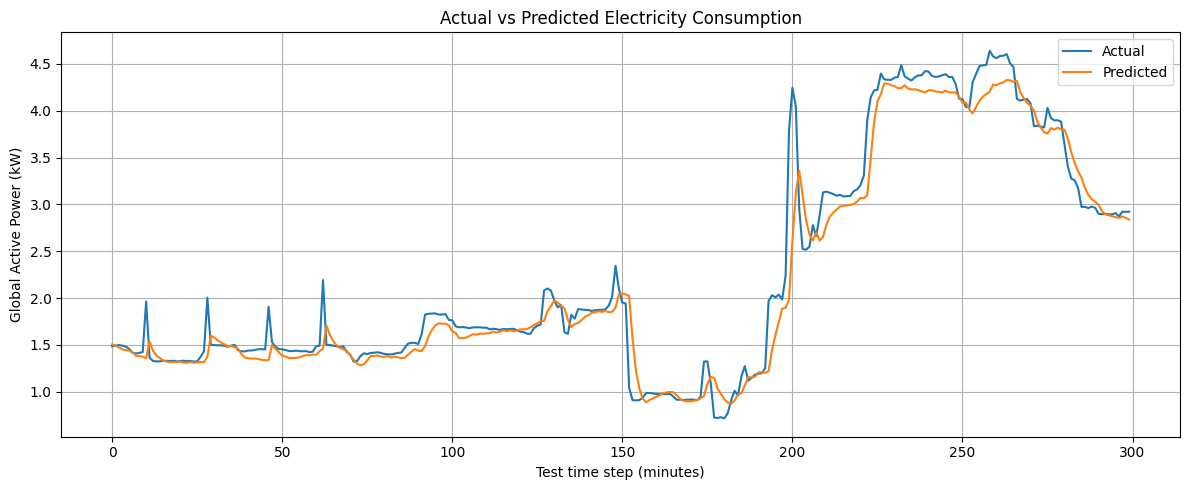

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(y_actual_kw[:300], label="Actual")
plt.plot(y_pred_kw[:300], label="Predicted")

plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Test time step (minutes)")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [13]:

# Final project verification

# 1. Check whether selected records are consecutive minute-level data
time_diff = data.index.to_series().diff().dropna()
print("All records exactly 1 minute apart:",
      (time_diff == pd.Timedelta(minutes=1)).all())
print("Largest time gap:", time_diff.max())

# 2. Check dataset and sequence sizes
print("Selected records:", len(data))
print("Features:", data.shape[1])
print("Training sequences:", len(X_train))
print("Validation sequences:", len(X_val))
print("Testing sequences:", len(X_test))

# 3. Check test predictions
print("Actual test values:", len(y_actual_kw))
print("Predicted test values:", len(y_pred_kw))

# 4. Final metrics
print(f"MAE: {mae:.4f} kW")
print(f"RMSE: {rmse:.4f} kW")


All records exactly 1 minute apart: True
Largest time gap: 0 days 00:01:00
Selected records: 10000
Features: 7
Training sequences: 6940
Validation sequences: 1440
Testing sequences: 1500
Actual test values: 1500
Predicted test values: 1500
MAE: 0.5929 kW
RMSE: 0.7785 kW


Total records: 10000
Number of features: 7
Continuous minute-level data: True

Test records: 1500
MAE: 0.5929 kW
RMSE: 0.7785 kW


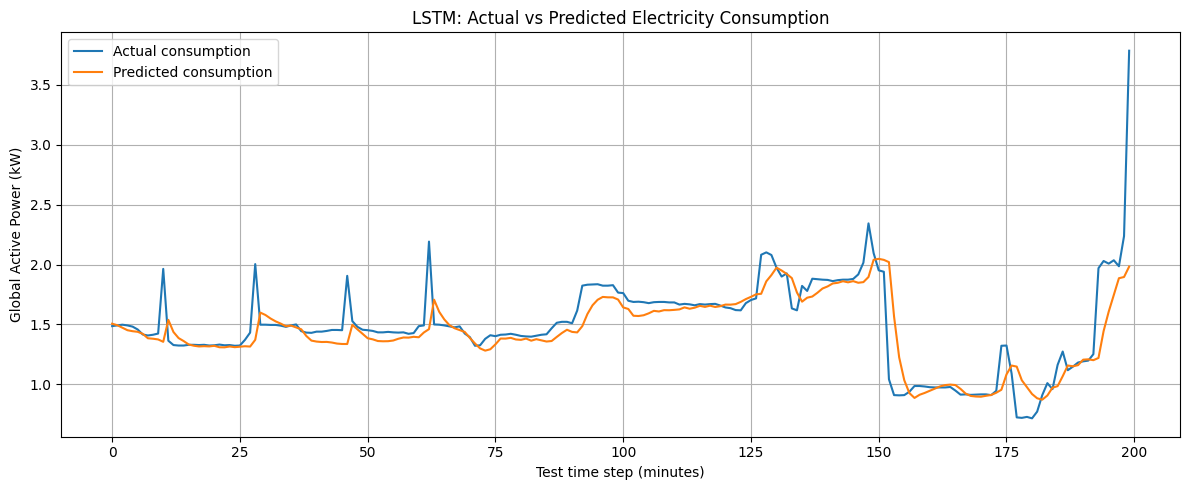

,Actual (kW),Predicted (kW)
0,1.486,1.506
1,1.492,1.494
2,1.498,1.473
3,1.492,1.452
4,1.482,1.444
5,1.458,1.439
6,1.416,1.421
7,1.408,1.385
8,1.414,1.381
9,1.424,1.375


In [14]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Verify dataset
print("Total records:", len(data))
print("Number of features:", data.shape[1])
print("Continuous minute-level data:",
      (data.index.to_series().diff().dropna()
       == pd.Timedelta(minutes=1)).all())

# 2. Predict unseen test records
pred_scaled = model.predict(X_test, verbose=0).flatten()

# Convert normalized values back to kW
target_min = scaler.data_min_[target_index]
target_max = scaler.data_max_[target_index]

actual = y_test * (target_max - target_min) + target_min
predicted = pred_scaled * (target_max - target_min) + target_min

# 3. Evaluate
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("\nTest records:", len(actual))
print(f"MAE: {mae:.4f} kW")
print(f"RMSE: {rmse:.4f} kW")

# 4. Show actual vs predicted
plt.figure(figsize=(12, 5))
plt.plot(actual[:200], label="Actual consumption")
plt.plot(predicted[:200], label="Predicted consumption")
plt.title("LSTM: Actual vs Predicted Electricity Consumption")
plt.xlabel("Test time step (minutes)")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 5. Display sample predictions
results = pd.DataFrame({
    "Actual (kW)": actual[:10],
    "Predicted (kW)": predicted[:10]
})
display(results.round(3))


In [15]:
test_range = target_max - target_min

normalized_mae = mae / test_range
score = (1 - normalized_mae) * 100

print(f"Normalized MAE-based score: {score:.2f}%")

Normalized MAE-based score: 92.25%


In [16]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Baseline: next minute = previous minute
baseline_scaled = X_test[:, -1, target_index]

target_min = scaler.data_min_[target_index]
target_max = scaler.data_max_[target_index]

baseline_kw = baseline_scaled * (target_max - target_min) + target_min

# Use the same test actual values for both models
lstm_mae = mean_absolute_error(y_actual_kw, y_pred_kw)
lstm_rmse = np.sqrt(mean_squared_error(y_actual_kw, y_pred_kw))

baseline_mae = mean_absolute_error(y_actual_kw, baseline_kw)
baseline_rmse = np.sqrt(mean_squared_error(y_actual_kw, baseline_kw))

comparison = pd.DataFrame({
    "Model": ["Persistence baseline", "LSTM"],
    "MAE (kW)": [baseline_mae, lstm_mae],
    "RMSE (kW)": [baseline_rmse, lstm_rmse]
})

display(comparison.round(4))


,Model,MAE (kW),RMSE (kW)
0,Persistence baseline,0.5045,0.8223
1,LSTM,0.5929,0.7785
